In [39]:
# IMPORTS -------------------------------------------------------------------- #
import os
import sys
from pathlib import Path
import re

import matplotlib.pyplot as plt
from matplotlib import rcParams
import numpy as np
import pandas as pd
import seaborn as sns

import utils

workspace,experiment=utils.workspace()

sys.path = [p for p in sys.path if "positron-python" not in p]

import anndata as ad
import scanpy as sc

SCANPY_WORKFLOW = True

In [40]:
# rcParams['figure.dpi'] = 150
sc.set_figure_params(dpi=80,facecolor='white', frameon=False, dpi_save=150, scanpy=True, fontsize=14, transparent=False, color_map=None)

In [41]:
if SCANPY_WORKFLOW:
    result_dir = experiment/"results/scanpy_workflow"
    identifier = "sc"
else:
    result_dir = experiment/"results/mad_workflow"
    identifier = "mad"
adata = ad.read_h5ad(result_dir/f"pbmc3k_{identifier}_qc.h5ad")
result_file = result_dir/f"pbmc3k_{identifier}_norm.h5ad"

# Normalization and Shifted Logarithm

In [42]:
# NORMALIZATION -------------------------------------------------------------- #
# Normalization + Shifted Logarithm
# Normalization: TP10K (adjust to sequencing depth)
# Shifted Logarithm: log1p (stabilize variance)
# ---------------------------------------------------------------------------- #
adata_norm = adata.copy()
adata_norm.layers["counts"] = adata_norm.X.copy()
sc.pp.normalize_total(adata_norm, target_sum=1e4)
sc.pp.log1p(adata_norm)
adata_norm

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'n_genes', 'outlier'
    var: 'gene_ids', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'scrublet', 'log1p'
    layers: None (.X), 'counts'

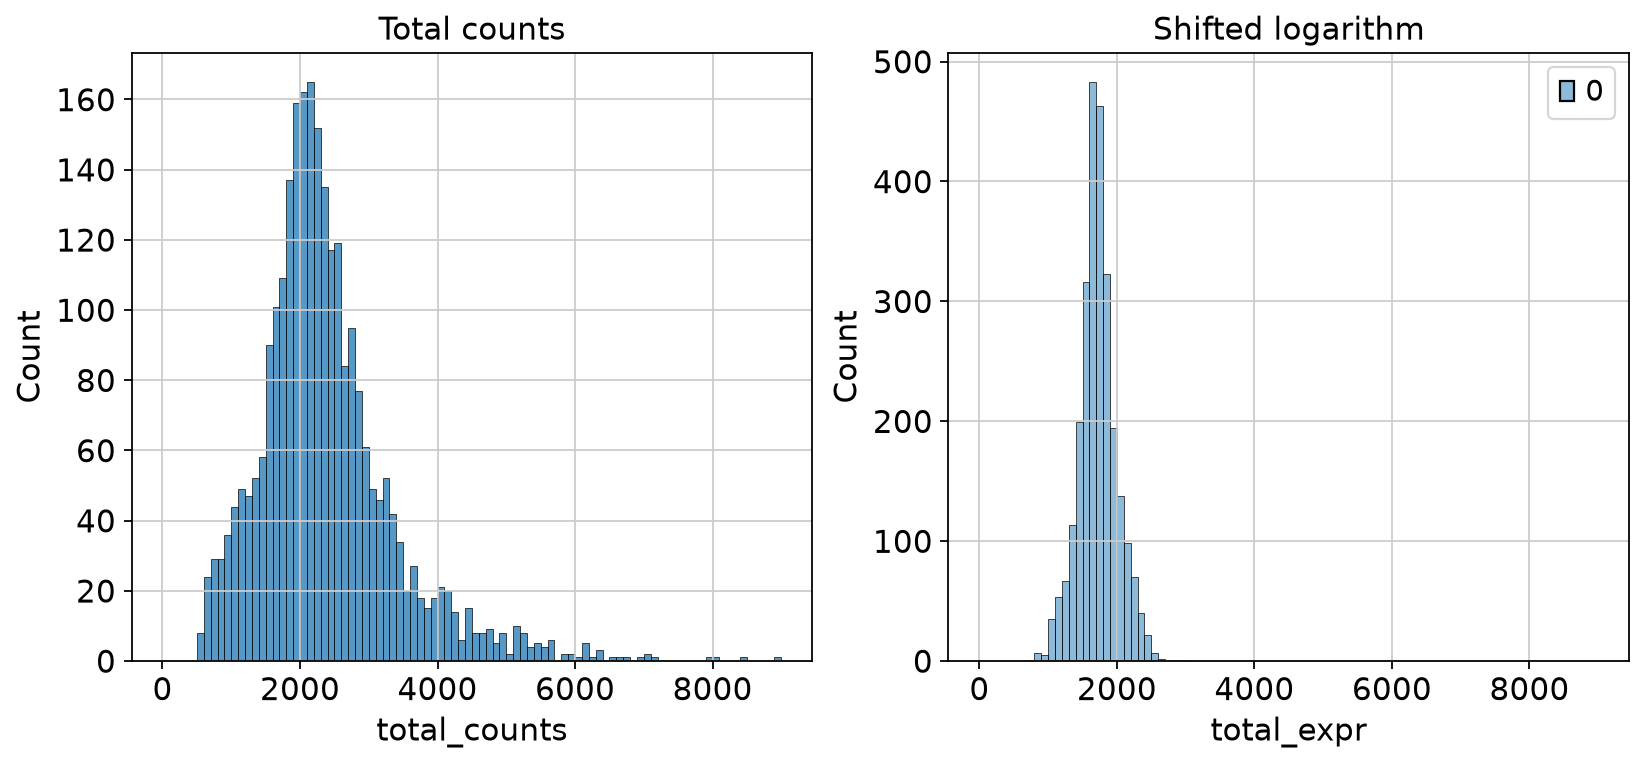

In [43]:
# PLOT TOTAL COUNTS / EXPRE PER CELL ----------------------------------------- #

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
# bin_edges = np.arange(0, adata.obs["total_counts"].max()+100, 100)
# p1 = sns.histplot(adata.obs["total_counts"], bins=bin_edges, kde=False, ax=axes[0])
# axes[0].set_title("Total counts (before QC)")
bin_edges = np.arange(0, adata_norm.obs["total_counts"].max()+100, 100)
p2 = sns.histplot(adata_norm.obs["total_counts"], bins=bin_edges, kde=False, ax=axes[0], legend=False)
axes[0].set_title("Total counts")
total_expr = adata_norm.X.sum(1)
bin_edges = np.arange(0, adata_norm.obs["total_counts"].max()+100, 100)
p3 = sns.histplot(total_expr, bins=bin_edges, kde=False, ax=axes[1])
axes[1].set_title("Shifted logarithm")
axes[1].set_xlabel('total_expr')
plt.savefig(experiment/f'figures/normalization/pbmc3k_{identifier}_shifted_log.png')
plt.show()

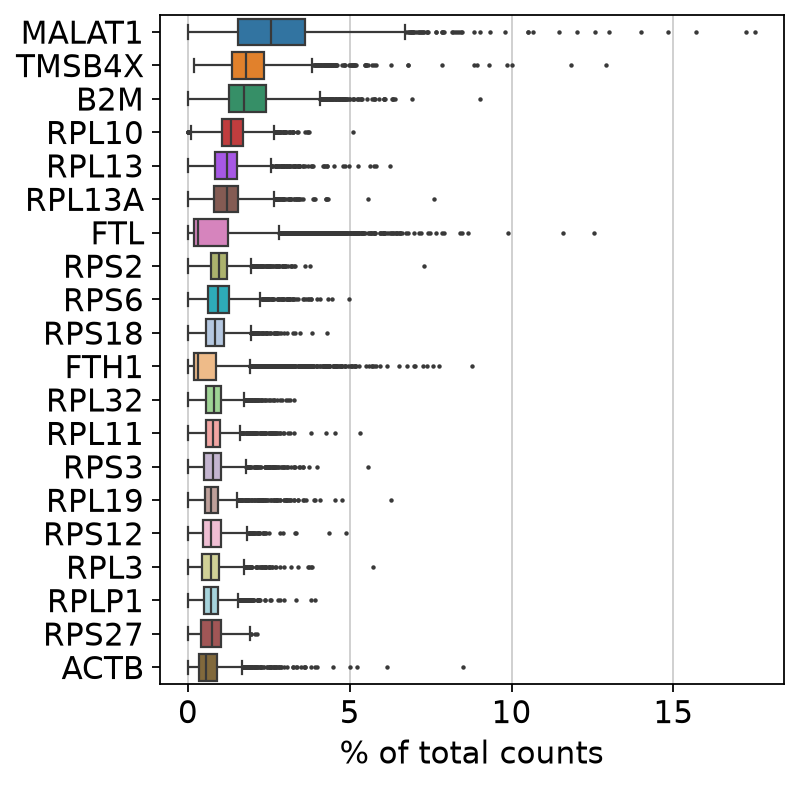

In [44]:
# HIGHEST EXPR --------------------------------------------------------------- #
sc.pl.highest_expr_genes(adata, n_top=20) # counts

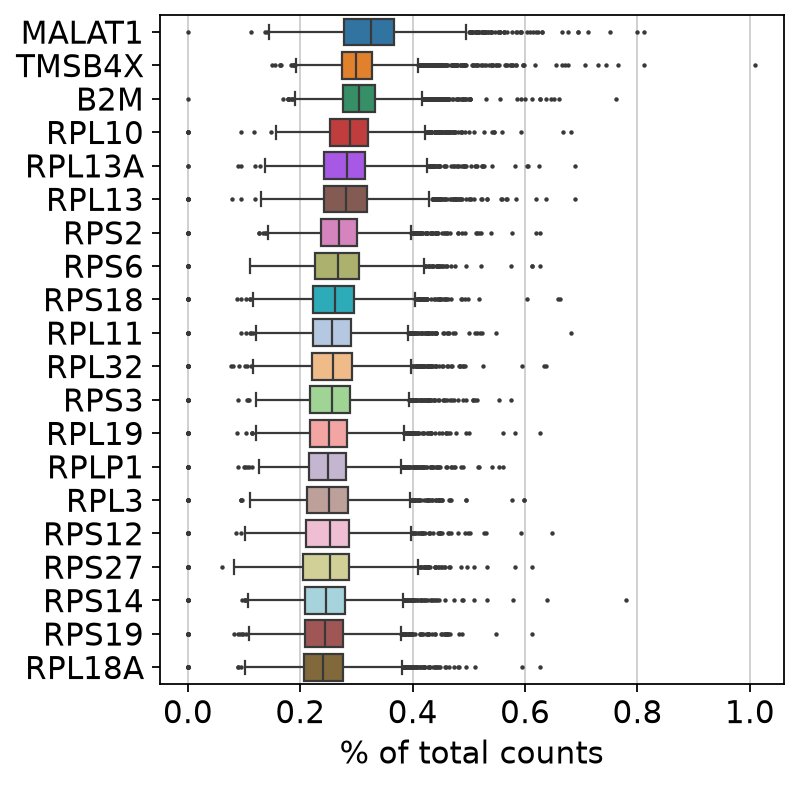

In [45]:
# HIGHEST EXPR --------------------------------------------------------------- #
sc.pl.highest_expr_genes(adata_norm, n_top=20) # normalized expression

# HVGs

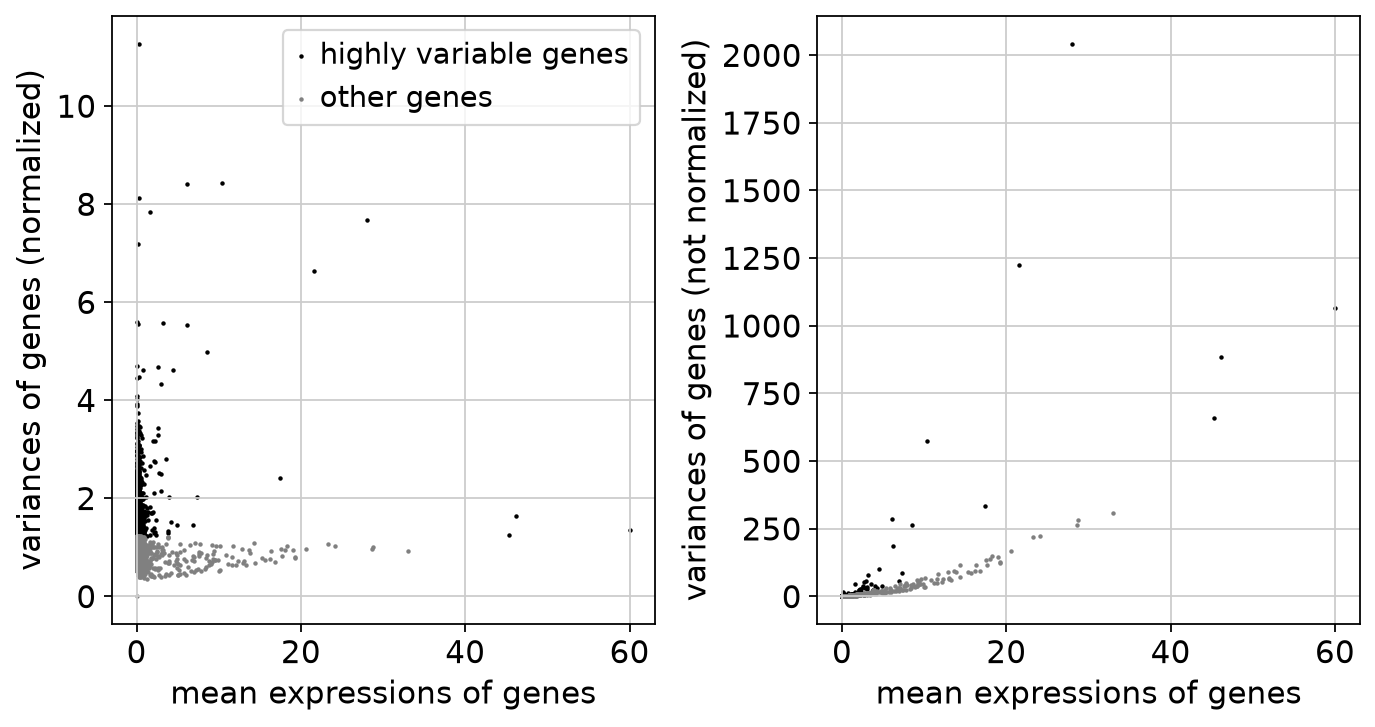

In [46]:
rcParams["figure.figsize"] = (5,5)
sc.pp.highly_variable_genes(
    adata_norm,
    layer='counts',
    n_top_genes=2000,
    flavor='seurat_v3',
)
sc.pl.highly_variable_genes(adata_norm)

# Sava data

In [47]:
adata_norm.write(result_file)


# HVGs

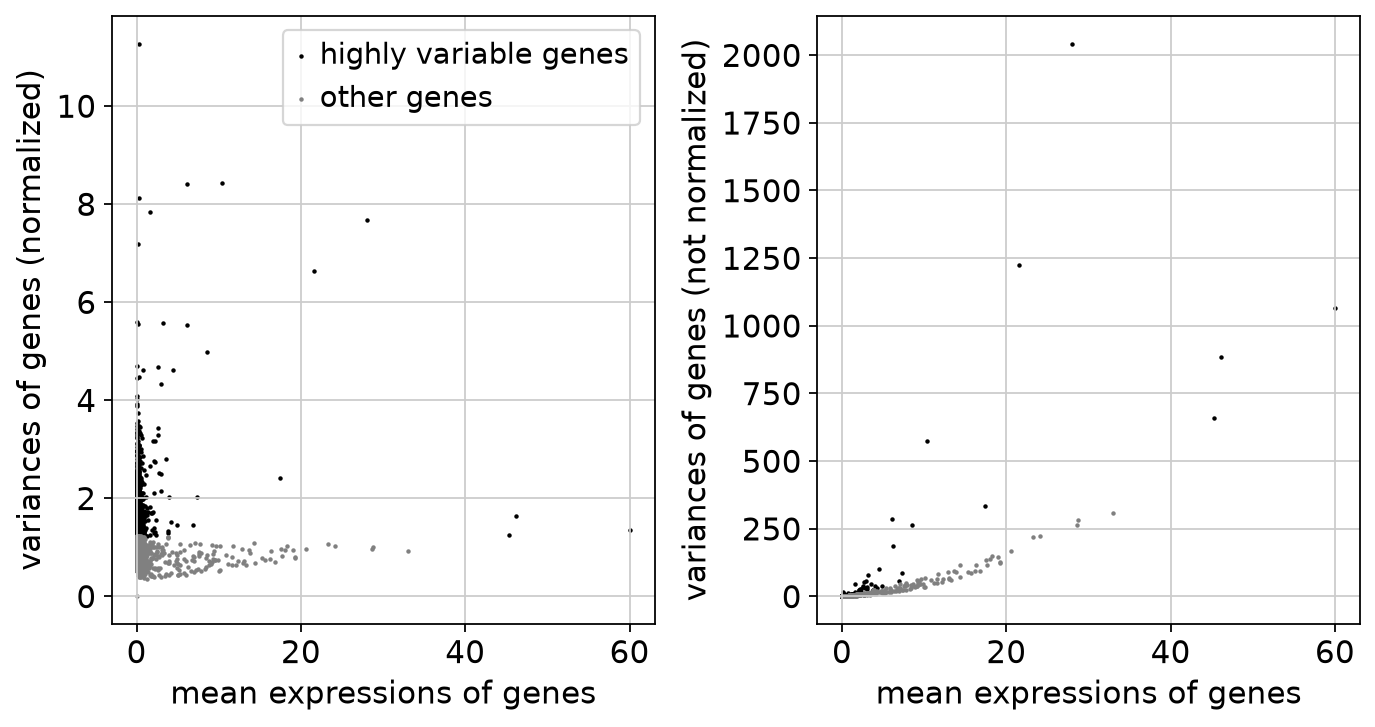

In [48]:
rcParams["figure.figsize"] = (5,5)
hvg_1 = sc.pp.highly_variable_genes(
    adata_norm,
    layer='counts',
    n_top_genes=2000,
    flavor='seurat_v3',
    inplace = False
)
sc.pp.highly_variable_genes(
    adata_norm,
    layer='counts',
    n_top_genes=2000,
    flavor='seurat_v3',
)
sc.pl.highly_variable_genes(adata_norm)

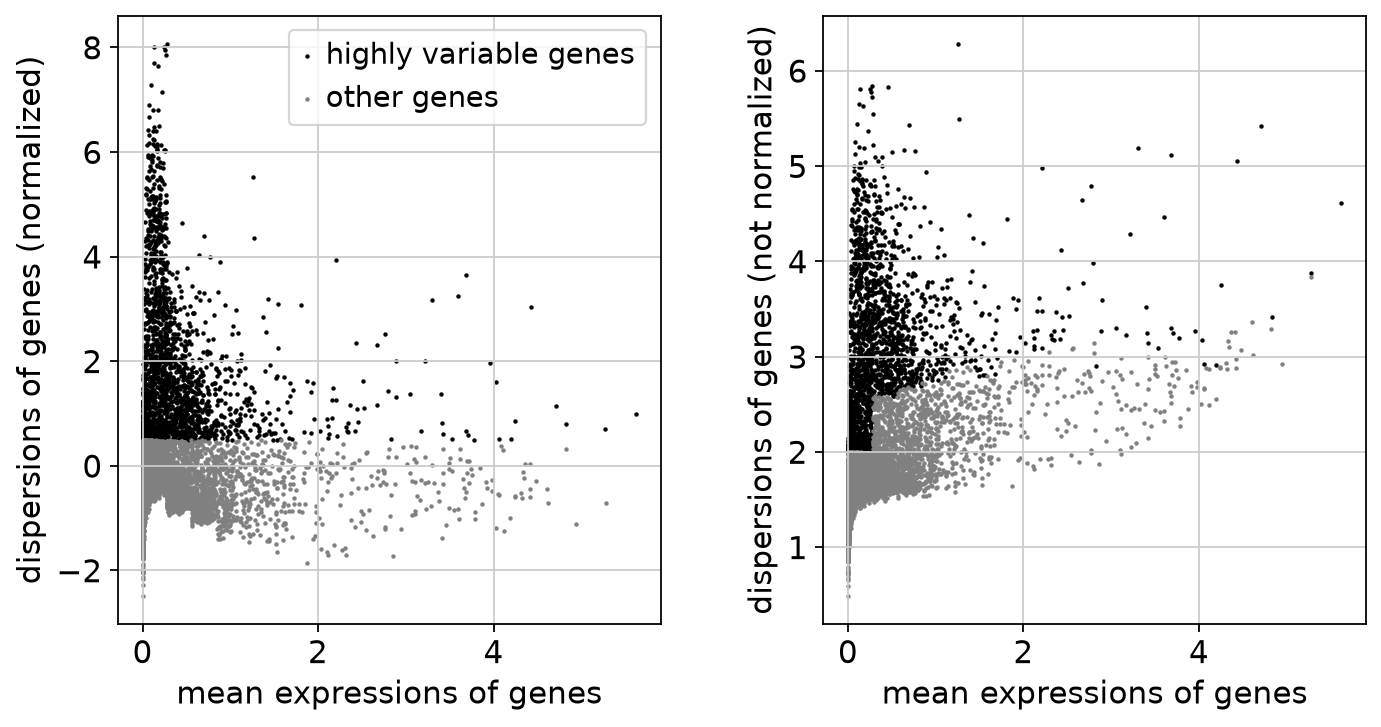

In [49]:
hvg_2 = sc.pp.highly_variable_genes(
    adata_norm,
    n_top_genes=2000,
    flavor='seurat',
    inplace = False
)
sc.pp.highly_variable_genes(
    adata_norm,
    n_top_genes=2000,
    flavor='seurat',
)
sc.pl.highly_variable_genes(adata_norm)

In [50]:
hvg_1_true = hvg_1.query('highly_variable == True')
hvg_2_true = hvg_2.query('highly_variable == True')
hvg_1_idx = set(hvg_1_true.index)
hvg_2_idx = set(hvg_2_true.index)
combined = (hvg_1_idx | hvg_2_idx)
print(len(combined))

2495


In [51]:
print(len(hvg_1_idx))
# hvg_1_true[~hvg_1_true.index.isin(hvg_2_idx)]
hvg_1_true[hvg_1_true.index.isin(hvg_1_idx-hvg_2_idx)]

2000


,means,variances,gene_name,highly_variable_rank,variances_norm,highly_variable
ISG15,1.205080,7.100513,ISG15,504.0,1.721487,True
MRPL20,0.338893,1.573390,MRPL20,407.0,1.833381,True
RP3-395M20.9,0.005307,0.007556,RP3-395M20.9,1811.0,1.310943,True
LRRC47,0.052312,0.195973,LRRC47,946.0,1.552752,True
GPR153,0.001895,0.002651,GPR153,1744.0,1.348552,True
...,...,...,...,...,...,...
DSCR9,0.001895,0.002651,DSCR9,1742.0,1.348552,True
MX2,0.145186,0.453316,MX2,1162.0,1.506112,True
MX1,0.309325,1.077585,MX1,1603.0,1.403501,True
AP001046.6,0.001895,0.002651,AP001046.6,1736.0,1.348552,True


In [52]:
print(len(hvg_2_idx))
# hvg_2_true[~hvg_2_true.index.isin(hvg_1_idx)]
hvg_2_true[hvg_2_true.index.isin(hvg_2_idx-hvg_1_idx)]

2000


,means,dispersions,mean_bin,dispersions_norm,highly_variable
TNFRSF4,0.277410,2.086050,"(-0.00562, 0.281]",0.665406,True
CA6,0.009766,2.004851,"(-0.00562, 0.281]",0.505081,True
NPPA-AS1,0.007839,2.095036,"(-0.00562, 0.281]",0.683149,True
TNFRSF1B,0.575939,3.662347,"(0.562, 0.843]",1.886701,True
CAPZB,1.646002,3.183822,"(1.406, 1.687]",1.213881,True
...,...,...,...,...,...
PARVB,0.261776,2.789326,"(-0.00562, 0.281]",2.054005,True
RABL2B,0.159578,2.585539,"(-0.00562, 0.281]",1.651634,True
BACH1,0.091598,2.048386,"(-0.00562, 0.281]",0.591040,True
KCNE1,0.026647,2.162786,"(-0.00562, 0.281]",0.816920,True


In [53]:
hvg_1 = sc.pp.highly_variable_genes(
    adata_norm,
    layer='counts',
    flavor='seurat_v3',
    inplace = False
)
hvg_2 = sc.pp.highly_variable_genes(
    adata_norm,
    flavor='seurat',
    inplace = False
)

hvg_1_ranks = hvg_1.variances_norm.rank(ascending=False, method='min').astype(int)
hvg_2_ranks = hvg_2.dispersions_norm.rank(ascending=False, method='min').astype('Int64')
print(f"{all([hvg_1_ranks[list(hvg_1_idx)].max() == 2000, hvg_2_ranks[list(hvg_2_idx)].max() == 2000])}")

False


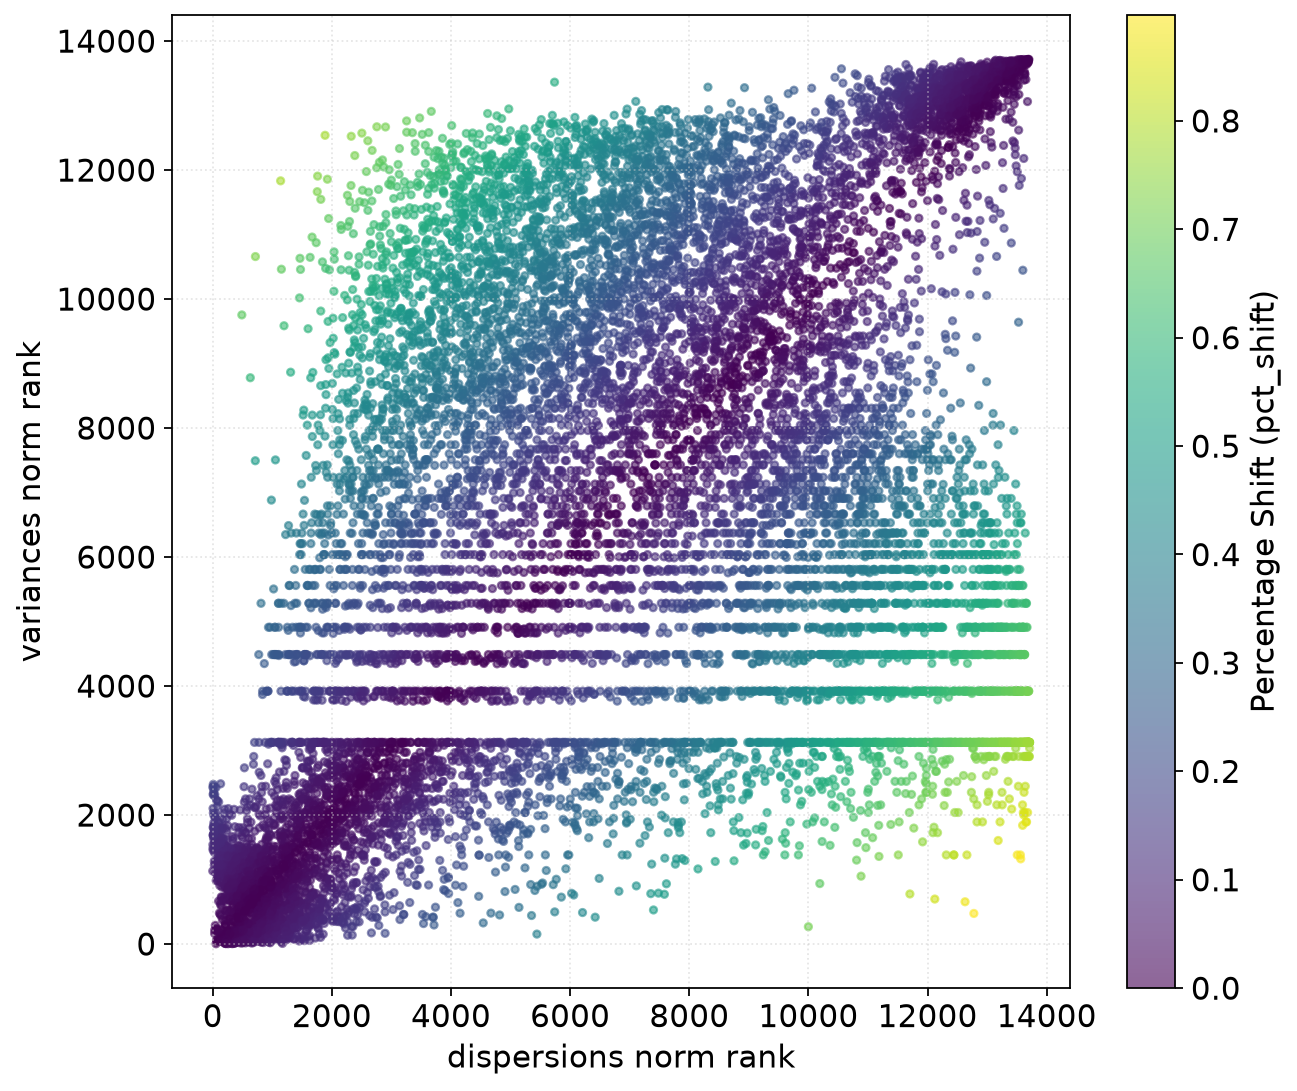

In [54]:
df_ranks = pd.concat([hvg_1_ranks,hvg_2_ranks],axis=1)
df_ranks['abs_diff'] = (hvg_1_ranks - hvg_2_ranks).abs()
df_ranks['pct_shift'] = df_ranks['abs_diff'] / df_ranks.shape[0]
plot_cols = ['variances_norm', 'dispersions_norm', 'pct_shift']
df_clean = df_ranks.dropna(subset=plot_cols).copy()
for col in plot_cols:
    df_clean[col] = df_clean[col].to_numpy(dtype='float64')

plt.figure(figsize=(9, 8))
scatter = plt.scatter(
    data=df_clean, 
    x='dispersions_norm',
    y='variances_norm', 
    c='pct_shift',
    cmap='viridis',
    # palette={'Normal Variance': '#A0AEC0', 'Drastic Change': '#E53E3E'},
    alpha=0.6,
    s=10
)
plt.colorbar(scatter, label='Percentage Shift (pct_shift)')
plt.xlabel("dispersions norm rank")
plt.ylabel("variances norm rank")
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

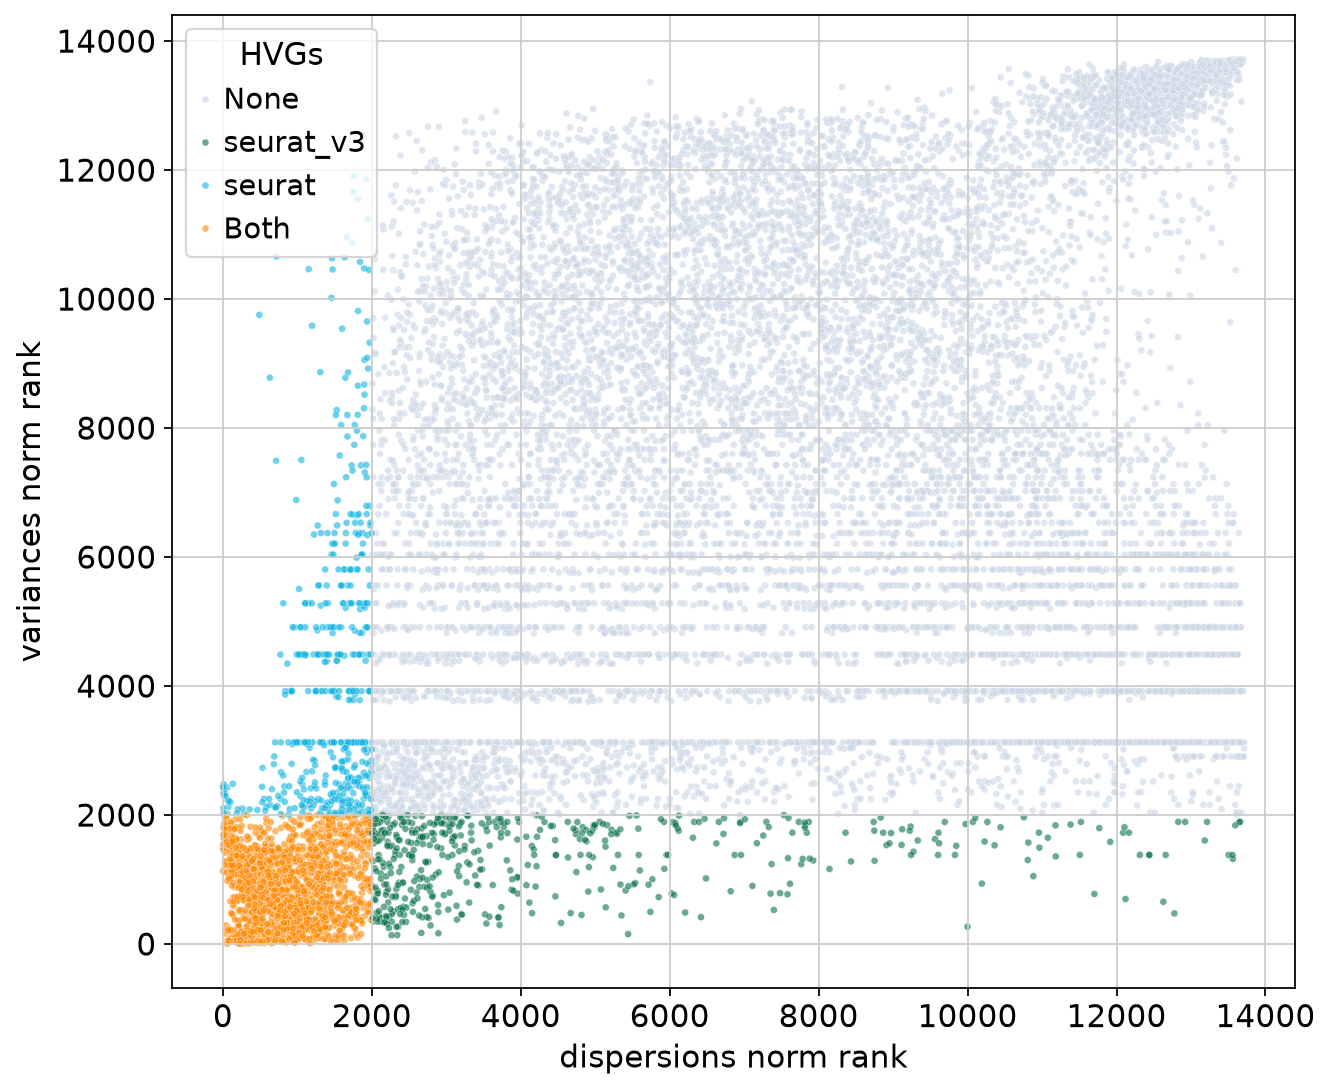

In [55]:
df_selected = df_clean[df_clean.index.isin(list(combined))]
in_group1 = df_clean.index.isin(list(hvg_1_true.index))
in_group2 = df_clean.index.isin(hvg_2_true.index)
conditions = [
    (in_group1 & in_group2),  # Matches both
    in_group1,  # Matches group 1 only
    in_group2,  # Matches group 2 only
]

labels = ["Both", "seurat_v3", "seurat"]
df_clean["HVGs"] = np.select(conditions, labels, default="None")

plt.figure(figsize=(9, 8))
sns.scatterplot(
    data=df_clean, 
    x='dispersions_norm',
    y='variances_norm', 
    hue='HVGs',
    # size="pct_shift",
    palette={'None': '#cbd6e5', 'Both': '#ff8801', "seurat_v3": '#077149',  "seurat": '#10b4e1'},
    alpha=0.6,
    s=10
)
plt.xlabel("dispersions norm rank")
plt.ylabel("variances norm rank")
plt.show()

In [56]:
df_ranks.query("variances_norm < 2000 & dispersions_norm < 4000 & pct_shift > 0.25")

,variances_norm,dispersions_norm,abs_diff,pct_shift


In [57]:
from collections import Counter
print(Counter(df_ranks.dispersions_norm.values).most_common(1))
print(Counter(df_ranks.variances_norm.values).most_common(1))

[(np.int64(11485), 1)]
[(np.int64(3123), 634)]
